In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
from tqdm.auto import tqdm

# Check GPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch version: 2.14.1+cu130
CUDA available: True
Device: cuda
GPU: NVIDIA GeForce RTX 3050 6GB Laptop GPU


In [2]:
# Define dataset paths
DATA_DIR = "data"
TRAIN_DIR = os.path.join(DATA_DIR, "train")
TEST_DIR = os.path.join(DATA_DIR, "test")

TRAIN_CSV = os.path.join(DATA_DIR, "Training_set.csv")
TEST_CSV = os.path.join(DATA_DIR, "Testing_set.csv")

# Check folders and files
print("Training folder exists:", os.path.exists(TRAIN_DIR))
print("Testing folder exists:", os.path.exists(TEST_DIR))
print("Training CSV exists:", os.path.exists(TRAIN_CSV))
print("Testing CSV exists:", os.path.exists(TEST_CSV))

# Load CSV files
train_df = pd.read_csv(TRAIN_CSV)
test_df = pd.read_csv(TEST_CSV)

# Display dataset information
print("\nTraining dataset shape:", train_df.shape)
print("Testing dataset shape:", test_df.shape)

print("\nTraining CSV columns:")
print(train_df.columns.tolist())

print("\nFirst 5 training rows:")
display(train_df.head())

print("\nFirst 5 testing rows:")
display(test_df.head())

Training folder exists: True
Testing folder exists: True
Training CSV exists: True
Testing CSV exists: True

Training dataset shape: (6499, 2)
Testing dataset shape: (2786, 1)

Training CSV columns:
['filename', 'label']

First 5 training rows:


,filename,label
0,Image_1.jpg,SOUTHERN DOGFACE
1,Image_2.jpg,ADONIS
2,Image_3.jpg,BROWN SIPROETA
3,Image_4.jpg,MONARCH
4,Image_5.jpg,GREEN CELLED CATTLEHEART



First 5 testing rows:


,filename
0,Image_1.jpg
1,Image_2.jpg
2,Image_3.jpg
3,Image_4.jpg
4,Image_5.jpg


In [3]:
# Display dataset information
print("Training dataset information:")
train_df.info()

print("\nMissing values:")
print(train_df.isnull().sum())

# Find the target column (butterfly class)
print("\nClass distribution:")

if "label" in train_df.columns:
    print(train_df["label"].value_counts())
    print("\nTotal butterfly classes:", train_df["label"].nunique())
else:
    print("Label column not found.")
    print("Available columns:", train_df.columns.tolist())

Training dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 6499 entries, 0 to 6498
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   filename  6499 non-null   str  
 1   label     6499 non-null   str  
dtypes: str(2)
memory usage: 101.7 KB

Missing values:
filename    0
label       0
dtype: int64

Class distribution:
label
MOURNING CLOAK    131
SLEEPY ORANGE     107
ATALA             100
BROWN SIPROETA     99
SCARCE SWALLOW     97
                 ... 
AMERICAN SNOOT     74
MALACHITE          73
GOLD BANDED        73
CRIMSON PATCH      72
WOOD SATYR         71
Name: count, Length: 75, dtype: int64

Total butterfly classes: 75


Total training images found: 6499


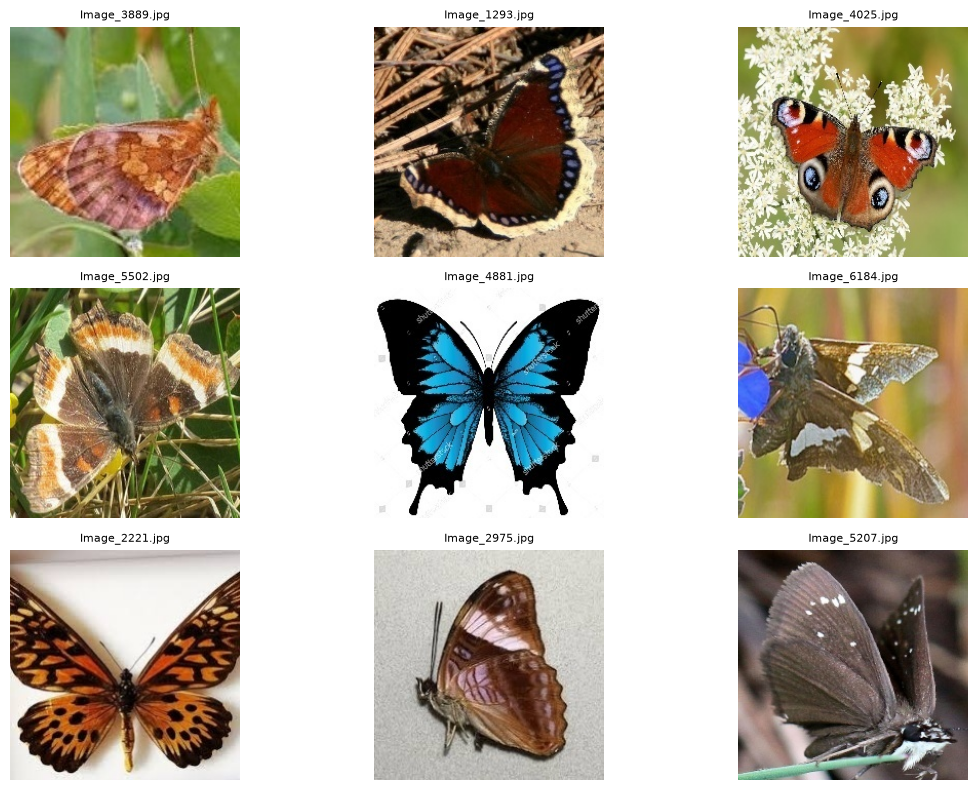

In [4]:
# Display sample butterfly images
import random

image_files = []

for root, dirs, files in os.walk(TRAIN_DIR):
    for file in files:
        if file.lower().endswith((".jpg", ".jpeg", ".png")):
            image_files.append(os.path.join(root, file))

print("Total training images found:", len(image_files))

# Display 9 random images
if image_files:
    samples = random.sample(image_files, min(9, len(image_files)))

    plt.figure(figsize=(12, 8))

    for i, image_path in enumerate(samples):
        img = Image.open(image_path).convert("RGB")

        plt.subplot(3, 3, i + 1)
        plt.imshow(img)
        plt.title(os.path.basename(image_path), fontsize=8)
        plt.axis("off")

    plt.tight_layout()
    plt.show()
else:
    print("No images found. Check the TRAIN_DIR path.")

In [5]:
# Image preprocessing
IMG_SIZE = 224
BATCH_SIZE = 16

train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

test_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

print("Image size:", IMG_SIZE, "x", IMG_SIZE)
print("Batch size:", BATCH_SIZE)
print("Image preprocessing configured successfully!")

Image size: 224 x 224
Batch size: 16
Image preprocessing configured successfully!


In [6]:
# Check the exact CSV columns and dataset paths
print("Training CSV columns:", train_df.columns.tolist())
print("Training folder:", TRAIN_DIR)
print("Sample training records:")
display(train_df.head())

print("\nTraining folder contents:")
print(os.listdir(TRAIN_DIR)[:10])

Training CSV columns: ['filename', 'label']
Training folder: data\train
Sample training records:


,filename,label
0,Image_1.jpg,SOUTHERN DOGFACE
1,Image_2.jpg,ADONIS
2,Image_3.jpg,BROWN SIPROETA
3,Image_4.jpg,MONARCH
4,Image_5.jpg,GREEN CELLED CATTLEHEART



Training folder contents:
['Image_1.jpg', 'Image_10.jpg', 'Image_100.jpg', 'Image_1000.jpg', 'Image_1001.jpg', 'Image_1002.jpg', 'Image_1003.jpg', 'Image_1004.jpg', 'Image_1005.jpg', 'Image_1006.jpg']


In [7]:
# Inspect the first training record
print("First training record:")
display(train_df.head(1))

# Check the CSV column names
print("\nColumns:", train_df.columns.tolist())

# Check whether the first image exists
filename_col = train_df.columns[0]
first_filename = train_df.iloc[0][filename_col]

image_path = os.path.join(TRAIN_DIR, str(first_filename))

print("\nFirst filename:", first_filename)
print("Expected image path:", image_path)
print("Image exists:", os.path.exists(image_path))

First training record:


,filename,label
0,Image_1.jpg,SOUTHERN DOGFACE



Columns: ['filename', 'label']

First filename: Image_1.jpg
Expected image path: data\train\Image_1.jpg
Image exists: True


In [8]:
# Encode butterfly species as numerical labels
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()
train_df["label_id"] = label_encoder.fit_transform(train_df["label"])

# Split into training and validation sets
train_split, val_split = train_test_split(
    train_df,
    test_size=0.2,
    random_state=42,
    stratify=train_df["label_id"]
)

# Reset indexes
train_split = train_split.reset_index(drop=True)
val_split = val_split.reset_index(drop=True)

# Display results
print("Total classes:", len(label_encoder.classes_))
print("Training images:", len(train_split))
print("Validation images:", len(val_split))

print("\nSample encoded labels:")
display(train_split.head())

Total classes: 75
Training images: 5199
Validation images: 1300

Sample encoded labels:


,filename,label,label_id
0,Image_4491.jpg,MANGROVE SKIPPER,40
1,Image_4801.jpg,GREAT JAY,32
2,Image_398.jpg,SLEEPY ORANGE,64
3,Image_6141.jpg,CLEOPATRA,17
4,Image_974.jpg,PAINTED LADY,49


In [9]:
class ButterflyDataset(Dataset):
    def __init__(self, dataframe, image_dir, transform=None):
        self.df = dataframe
        self.image_dir = image_dir
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, index):
        row = self.df.iloc[index]

        image_path = os.path.join(
            self.image_dir, row["filename"]
        )

        image = Image.open(image_path).convert("RGB")
        label = int(row["label_id"])

        if self.transform:
            image = self.transform(image)

        return image, label


# Create datasets
train_dataset = ButterflyDataset(
    train_split, TRAIN_DIR, train_transform
)

val_dataset = ButterflyDataset(
    val_split, TRAIN_DIR, test_transform
)

# Create DataLoaders
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))

Training batches: 325
Validation batches: 82


In [10]:
class ButterflyCNN(nn.Module):
    def __init__(self, num_classes):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(64, 128, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.AdaptiveAvgPool2d((1, 1))
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.3),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)


num_classes = len(label_encoder.classes_)

model = ButterflyCNN(num_classes).to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

print("CNN model created!")
print("Number of classes:", num_classes)
print("Training device:", device)

CNN model created!
Number of classes: 75
Training device: cuda


In [11]:
EPOCHS = 13

train_losses, val_losses = [], []
train_accuracies, val_accuracies = [], []

for epoch in range(EPOCHS):
    # Training
    model.train()
    running_loss, correct, total = 0.0, 0, 0

    for images, labels in tqdm(train_loader, desc=f"Epoch {epoch+1}/{EPOCHS}"):
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)
        correct += (outputs.argmax(1) == labels).sum().item()
        total += labels.size(0)

    train_loss = running_loss / total
    train_acc = correct / total

    # Validation
    model.eval()
    running_loss, correct, total = 0.0, 0, 0

    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)

            running_loss += loss.item() * images.size(0)
            correct += (outputs.argmax(1) == labels).sum().item()
            total += labels.size(0)

    val_loss = running_loss / total
    val_acc = correct / total

    train_losses.append(train_loss)
    val_losses.append(val_loss)
    train_accuracies.append(train_acc)
    val_accuracies.append(val_acc)

    print(
        f"Epoch {epoch+1}/{EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.2%} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.2%}"
    )

Epoch 1/13:   0%|          | 0/325 [00:00<?, ?it/s]

Epoch 1/13 | Train Loss: 4.0930 | Train Acc: 4.37% | Val Loss: 3.7806 | Val Acc: 7.54%


Epoch 2/13:   0%|          | 0/325 [00:00<?, ?it/s]

Epoch 2/13 | Train Loss: 3.6743 | Train Acc: 10.23% | Val Loss: 3.5416 | Val Acc: 13.85%


Epoch 3/13:   0%|          | 0/325 [00:00<?, ?it/s]

...

Epoch 11/13 | Train Loss: 2.1342 | Train Acc: 41.83% | Val Loss: 2.0737 | Val Acc: 44.62%


Epoch 12/13:   0%|          | 0/325 [00:00<?, ?it/s]

Epoch 12/13 | Train Loss: 2.0569 | Train Acc: 44.01% | Val Loss: 2.0315 | Val Acc: 47.92%


Epoch 13/13:   0%|          | 0/325 [00:00<?, ?it/s]

Epoch 13/13 | Train Loss: 1.9968 | Train Acc: 46.62% | Val Loss: 1.9128 | Val Acc: 52.08%


In [12]:
print("Final Training Accuracy:", f"{train_accuracies[-1]*100:.2f}%")
print("Final Validation Accuracy:", f"{val_accuracies[-1]*100:.2f}%")
print("Final Training Loss:", f"{train_losses[-1]:.4f}")
print("Final Validation Loss:", f"{val_losses[-1]:.4f}")


Final Training Accuracy: 46.62%
Final Validation Accuracy: 52.08%
Final Training Loss: 1.9968
Final Validation Loss: 1.9128


In [13]:
import os
import json
import torch

os.makedirs("models", exist_ok=True)

torch.save(model.state_dict(), "models/butterfly_cnn.pth")

with open("models/class_names.json", "w") as f:
    json.dump(label_encoder.classes_.tolist(), f)

print("Model and class names saved successfully!")

Model and class names saved successfully!
